In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("penguins.csv")

In [2]:
df.head(5)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 24.9 KB


In [4]:
df.shape

(344, 7)

In [5]:
df = df.rename(columns={'sex': 'gender'})
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   gender             333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 24.9 KB


In [6]:
#Finding null Values
df.isnull().sum()


species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
gender               11
dtype: int64

In [7]:
# deleting the null values
#df[['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']] = df[['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']].fillna(df[['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']].mean())


df = df.dropna()

In [8]:
df.isnull().sum()


species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
gender               0
dtype: int64

In [9]:
df.shape

(333, 7)

<Axes: xlabel='body_mass_g'>

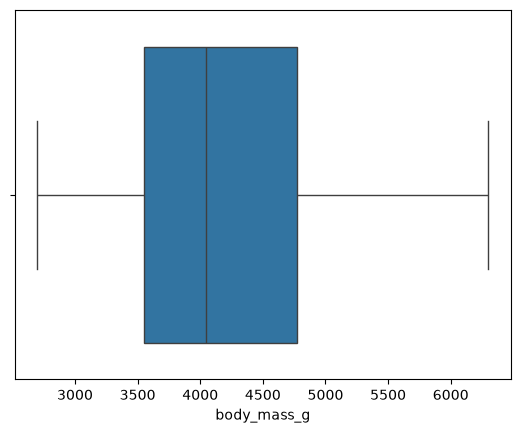

In [12]:
sns.boxplot(x=df['body_mass_g'])

Correlation: 0.87


<Axes: xlabel='flipper_length_mm', ylabel='body_mass_g'>

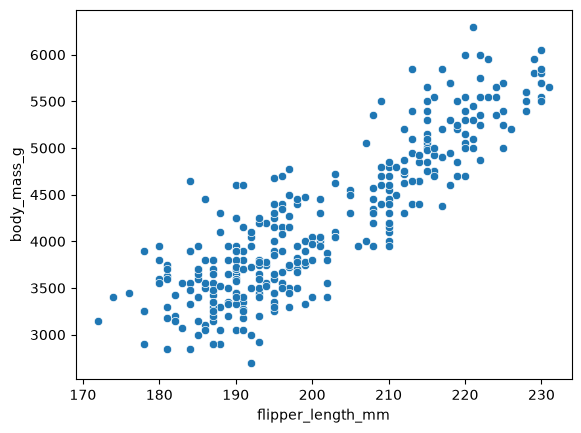

In [13]:
correlation = df['flipper_length_mm'].corr(df['body_mass_g'])
print("Correlation:", round(correlation, 2))  # Result 0.87 aayega

sns.scatterplot(x='flipper_length_mm', y='body_mass_g', data=df)

In [20]:
print(df.groupby("species")[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]].agg(['mean', 'min', 'max']))

print("\n Average weight of Male and Female")
print(df.groupby(['species', 'gender'])['body_mass_g'].mean())

          bill_length_mm             bill_depth_mm              \
                    mean   min   max          mean   min   max   
species                                                          
Adelie         38.823973  32.1  46.0     18.347260  15.5  21.5   
Chinstrap      48.833824  40.9  58.0     18.420588  16.4  20.8   
Gentoo         47.568067  40.9  59.6     14.996639  13.1  17.3   

          flipper_length_mm                body_mass_g                  
                       mean    min    max         mean     min     max  
species                                                                 
Adelie           190.102740  172.0  210.0  3706.164384  2850.0  4775.0  
Chinstrap        195.823529  178.0  212.0  3733.088235  2700.0  4800.0  
Gentoo           217.235294  203.0  231.0  5092.436975  3950.0  6300.0  

 Average weight of Male and Female
species    gender
Adelie     Female    3368.835616
           Male      4043.493151
Chinstrap  Female    3527.205882
           M

In [11]:
print(df.groupby("species")["island"].value_counts())

species    island   
Adelie     Dream         55
           Torgersen     47
           Biscoe        44
Chinstrap  Dream         68
Gentoo     Biscoe       119
Name: count, dtype: int64


C:\Users\Lakha Trader\AppData\Local\Temp\ipykernel_3884\1651126131.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


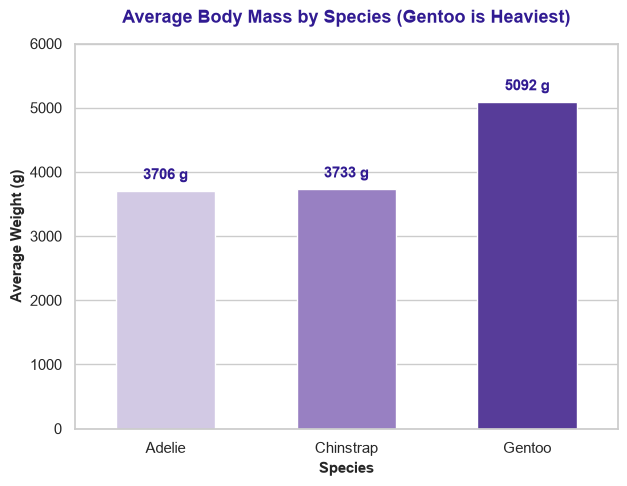

In [24]:
purple_shades = {
    'Adelie': '#D1C4E9',     # Light Purple
    'Chinstrap': '#9575CD',  # Medium Purple
    'Gentoo': '#512DA8'      # Dark Purple (Gentoo heaviest dikhane ke liye)
}


plt.figure(figsize=(7, 5))
sns.set_theme(style='whitegrid')

ax = sns.barplot(
    data=df,
    x='species',
    y='body_mass_g',
    palette=purple_shades,
    estimator='mean',
    errorbar=None,
    width=0.55
)

for p in ax.patches:
    weight = int(p.get_height())
    ax.annotate(
        f'{weight} g',
        (p.get_x() + p.get_width() / 2., weight),
        ha='center',
        va='bottom',
        fontsize=11,
        fontweight='bold',
        color='#311B92',
        xytext=(0, 6),
        textcoords='offset points'
    )
plt.title('Average Body Mass by Species (Gentoo is Heaviest)', fontsize=13, fontweight='bold', color='#311B92', pad=15)
plt.xlabel('Species', fontsize=11, fontweight='bold')
plt.ylabel('Average Weight (g)', fontsize=11, fontweight='bold')
plt.ylim(0, 6000)

plt.show()

-The Gentoo species are the heaviest.
-The Adile species founds on all three islands given in the data set(Dream,Biscoe,Torgersen).